# 선정 계열 모델 비교 — 2. 선정된 계열의 모델 비교

## 배경

3번 노트북에서 90% 폭 비교(부트스트랩 80.8%)와 Winkler(90%) 재검증 둘 다
**시계열(Auto-ARIMA)·회귀**를 상위로 꼽았다. 이 두 계열 안에서 세부 모델을
비교해 최종 모델을 좁힌다.

## 목적

- 2-1: 시계열 5종(ARIMA AIC/BIC·ETS·Theta·RW+drift) + 회귀 4종(OLS/Ridge/
  Lasso/ElasticNet) 백테스트
- 2-2: 90% 튜닝 후 폭 비교 + 부트스트랩
- 2-2 최종: Winkler(90%)로 재검증
- 2-3: 최종 선정

## 비교 대상 9개 모델

| 계열 | 모델 | 선정 이유 |
|---|---|---|
| 시계열 | ARIMA(AIC/BIC), ETS, Theta, RW+drift | 표준 자동선택·벤치마크 기법들 |
| 회귀 | OLS/Ridge/Lasso/ElasticNet(AR(2)) | 정규화 강도별 비교 |

공통 `fit_forecast(values, h)`로 통일, 변수별 수동 튜닝 없음.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
}
FAMILY_LABELS = {
    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "ets": "시계열-ETS",
    "theta": "시계열-Theta", "rw_drift": "시계열-RW+drift",
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")  # 노트북 실행 cwd는 notebooks/ 폴더 기준
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

H = 7           # 예측 horizon (7분기)
MIN_TRAIN = 20  # 백테스트 origin 시작 전 최소 학습 길이
LAG = 2         # 회귀 계열이 쓰는 AR lag 차수

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


## 2-1. 모델 정의 및 백테스트

3번 노트북과 동일한 확장윈도우 백테스트를 재사용한다 — 동일 origin 범위(MIN_TRAIN=20),
동일 horizon(H=7). 회귀 계열은 3번 노트북과 같은 방식(AR(2) lag 특성으로 학습한 뒤
recursive로 7스텝 예측)을 쓴다.


In [2]:
def fc_arima_aic(values, h=H):
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore",
                           information_criterion="aic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_arima_bic(values, h=H):
    # BIC는 AIC보다 파라미터 수에 더 강한 벌점을 줘서 소량 데이터에서 더 단순한 order를 고르는 경향
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore",
                           information_criterion="bic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_ets(values, h=H):
    # 추세 없음 / 추세 있음(damped 아님) / 추세+damped, 세 구성을 AIC로 자동 선택
    best_aic, best_fc = np.inf, None
    for trend, damped in [(None, False), ("add", False), ("add", True)]:
        try:
            kwargs = dict(trend=trend, initialization_method="estimated")
            if trend == "add":
                kwargs["damped_trend"] = damped
            fit = ExponentialSmoothing(values, **kwargs).fit()
            if fit.aic < best_aic:
                best_aic, best_fc = fit.aic, fit.forecast(h)
        except Exception:
            continue
    return best_fc if best_fc is not None else np.repeat(values[-1], h)

def fc_theta(values, h=H):
    # 표준 Theta method는 SES + (OLS 추세 기울기/2)의 외삽과 수학적으로 동치임(Hyndman & Billah, 2003)
    n = len(values)
    slope = np.polyfit(np.arange(n), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    drift = (slope / 2) * np.arange(1, h + 1)
    return ses_fc + drift

def fc_rw_drift(values, h=H):
    # naive(추세 없음)의 가장 단순한 확장: 과거 평균 변화량(drift)만큼 매 분기 더해줌
    drift = np.mean(np.diff(values))
    return values[-1] + drift * np.arange(1, h + 1)

def _lag_xy(values, lag=LAG):
    # AR(lag) 학습 데이터 생성: X=과거 lag개 값, y=다음 값
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    # 1-step 모델 하나를 학습한 뒤, 예측값을 다음 입력으로 재사용하며 h번 반복(recursive)
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_reg_ols(values, h=H):
    # 회귀 baseline: 선형회귀(OLS) 기반 AR(2), recursive
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_reg_ridge(values, h=H):
    # L2 정규화: lag1/lag2 사이 다중공선성을 완화. alpha는 RidgeCV로 자동 선택(임의 값 방지)
    return _recursive_forecast(lambda X, y: RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X, y), values, h)

def fc_reg_lasso(values, h=H):
    # L1 정규화: 불필요한 lag를 0으로 눌러 자동 변수선택. alpha는 LassoCV로 자동 선택
    return _recursive_forecast(
        lambda X, y: LassoCV(alphas=np.logspace(-3, 3, 13), max_iter=5000).fit(X, y), values, h
    )

def fc_reg_elastic(values, h=H):
    # L1+L2 혼합 정규화(Ridge와 Lasso 사이). alpha·l1_ratio 모두 ElasticNetCV로 자동 선택
    return _recursive_forecast(
        lambda X, y: ElasticNetCV(alphas=np.logspace(-3, 3, 13), l1_ratio=[.1, .5, .7, .9, .95, 1], max_iter=5000).fit(X, y),
        values, h,
    )

MODELS = {
    "arima_aic": fc_arima_aic, "arima_bic": fc_arima_bic, "ets": fc_ets, "theta": fc_theta, "rw_drift": fc_rw_drift,
    "reg_ols": fc_reg_ols, "reg_ridge": fc_reg_ridge, "reg_lasso": fc_reg_lasso, "reg_elastic": fc_reg_elastic,
}
print("모델 9개 정의 완료:", list(MODELS.keys()))


모델 9개 정의 완료: ['arima_aic', 'arima_bic', 'ets', 'theta', 'rw_drift', 'reg_ols', 'reg_ridge', 'reg_lasso', 'reg_elastic']


In [3]:
t0 = time.time()
records = []
for c in COLS:
    vals = series[c]
    n = len(vals)
    for origin in range(MIN_TRAIN, n - H + 1):  # 확장윈도우: 가능한 모든 시점을 origin으로
        train, actual = vals[:origin], vals[origin:origin + H]
        for name, fn in MODELS.items():
            try:
                fc = fn(train, H)
            except Exception:
                fc = np.repeat(train[-1], H)  # 학습/예측 실패 시 안전하게 마지막 값으로 대체
            err = actual - fc
            for h in range(1, H + 1):
                records.append({"var": c, "model": name, "origin": origin, "h": h, "err": err[h - 1]})
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")


X1 완료 (20초 경과)


X2 완료 (71초 경과)


X3 완료 (137초 경과)


X4 완료 (233초 경과)


X5 완료 (271초 경과)


X6 완료 (348초 경과)
총 소요시간: 348초, 총 12915개 오차 기록


In [4]:
rmse = err_df.groupby(["var", "model"])["err"].apply(lambda e: np.sqrt(np.mean(e**2))).unstack()
rmse = rmse.rename(index=LABELS, columns=FAMILY_LABELS).round(3)
print("변수 x 모델 RMSE (참고용):")
display(rmse)

overall = err_df.groupby("model")["err"].apply(lambda e: np.sqrt(np.mean(e**2))).rename(index=FAMILY_LABELS)
overall = overall.sort_values().round(3).to_frame("전체 평균 RMSE")
print("전체 평균 RMSE (참고용, 낮을수록 좋음):")
display(overall)


변수 x 모델 RMSE (참고용):


model,시계열-ARIMA(AIC),시계열-ARIMA(BIC),시계열-ETS,회귀-ElasticNet,회귀-Lasso,회귀-OLS,회귀-Ridge,시계열-RW+drift,시계열-Theta
var,,,,,,,,,
X1,181.381,182.379,227.931,186.020,185.946,185.796,185.781,279.583,229.825
X2,0.007,0.007,0.012,0.009,0.009,0.008,0.008,0.010,0.010
X3,332.868,354.985,381.107,317.353,316.928,316.292,316.498,326.225,316.472
X4,0.038,0.038,0.048,0.039,0.043,0.036,0.036,0.048,0.045
X5,0.069,0.068,0.077,0.062,0.061,0.067,0.067,0.083,0.078
X6,0.012,0.012,0.011,0.021,0.021,0.013,0.013,0.011,0.011


전체 평균 RMSE (참고용, 낮을수록 좋음):


,전체 평균 RMSE
model,
회귀-OLS,148.826
회귀-Ridge,148.895
회귀-Lasso,149.080
회귀-ElasticNet,149.245
시계열-ARIMA(AIC),153.859
시계열-Theta,158.473
시계열-ARIMA(BIC),162.032
시계열-RW+drift,173.878
시계열-ETS,180.145


**해석(참고용)**: 3번 노트북 원칙대로 RMSE는 최종 선정 기준으로 쓰지 않는다 —
참고용으로만 본다. 실제 선정은 아래 2-2의 walk-forward 커버리지·구간폭으로 한다.


## 2-2. Walk-forward 커버리지 90% 튜닝 + 구간폭 비교

3번 노트북에서 검증한 절차를 그대로 재사용한다: raw 커버리지로는 순위를 매기지 않고,
각 모델을 safety 배율로 walk-forward 90%에 맞게 튜닝한 뒤 **그때의 구간폭**만으로
비교한다.


In [5]:
INITIAL_CALIB = 15  # 이 개수만큼은 순수 calibration 전용으로 쌓아두고 시작

def walkforward_coverage_for(name, quantile=0.90, safety=1.0):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_origins = origins[:i]   # 검증 시점보다 앞선 origin만 사용 (미래 정보 누출 없음)
            test_origin = origins[i]
            calib_errs = g[g["origin"].isin(calib_origins)]
            sigma_h = calib_errs.groupby("h")["err"].std()

            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            calib_z = calib_pivot.div(sigma_h, axis=1)
            k = calib_z.abs().max(axis=1).quantile(quantile) * safety

            test_errs = g[g["origin"] == test_origin].set_index("h")["err"]
            test_max_z = (test_errs / sigma_h).abs().max()

            rows.append({
                "var": v, "origin": test_origin, "k": k,
                "sigma_h_mean": sigma_h.mean(), "covered": test_max_z <= k,
            })
    return pd.DataFrame(rows)

def tune_safety(name, target=0.90, grid=np.arange(1.0, 3.01, 0.02)):
    best = None
    for s in grid:
        wf = walkforward_coverage_for(name, quantile=0.90, safety=s)
        cov = wf["covered"].mean()
        rel_width = (2 * wf["k"] * wf["sigma_h_mean"]) / wf["var"].map(var_std)
        gap = abs(cov - target)
        if best is None or gap < best["gap"]:
            best = {"safety": round(s, 2), "커버리지(%)": round(cov * 100, 1),
                    "평균 상대폭": round(rel_width.mean(), 2), "gap": gap}
    return best

t0 = time.time()
tune_rows = []
for name in MODELS:
    best = tune_safety(name)
    tune_rows.append({"모델": FAMILY_LABELS[name], **best})
print(f"튜닝 소요시간: {time.time()-t0:.0f}초")

tune_df = pd.DataFrame(tune_rows).set_index("모델").drop(columns="gap")
tune_df = tune_df.sort_values("평균 상대폭")
display(tune_df)

winner = tune_df.index[0]
print(f"1위 모델: {winner}")


튜닝 소요시간: 321초


,safety,커버리지(%),평균 상대폭
모델,,,
시계열-ARIMA(BIC),1.52,88.7,6.52
시계열-ARIMA(AIC),1.56,89.6,6.61
시계열-Theta,1.42,89.6,6.77
회귀-OLS,1.66,89.6,6.89
회귀-Ridge,1.62,89.6,6.92
시계열-RW+drift,1.38,90.4,6.93
회귀-ElasticNet,1.58,89.6,6.97
회귀-Lasso,1.58,89.6,7.01
시계열-ETS,1.46,91.3,7.02


1위 모델: 시계열-ARIMA(BIC)


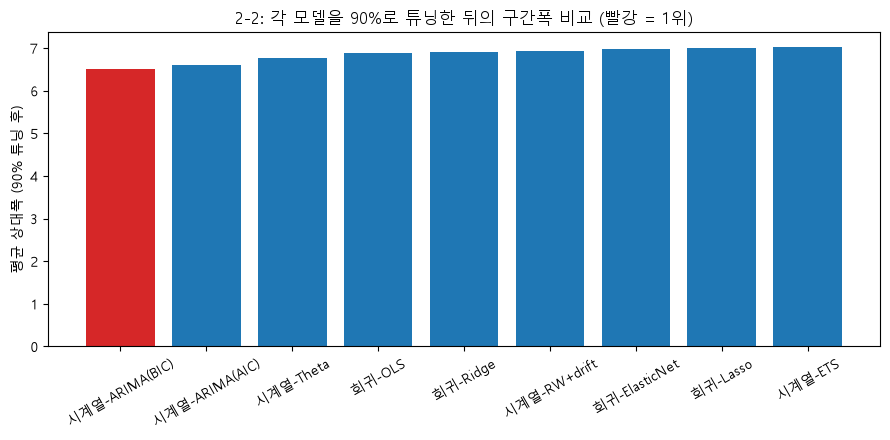

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#d62728" if n == winner else "#1f77b4" for n in tune_df.index]
ax.bar(tune_df.index, tune_df["평균 상대폭"], color=colors)
ax.set_ylabel("평균 상대폭 (90% 튜닝 후)")
ax.set_title("2-2: 각 모델을 90%로 튜닝한 뒤의 구간폭 비교 (빨강 = 1위)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


### 모델별 90% 구간을 한 변수에 겹쳐서 시각 비교

표·막대그래프만으로는 "구간이 실제로 얼마나 다른지" 감이 안 오니, 6개 변수 중 변동이
크고 문제가 뚜렷했던 **X3**(X3_l1) 하나를 골라 9개 모델의 90% 구간을 나란히
그려서 비교한다.


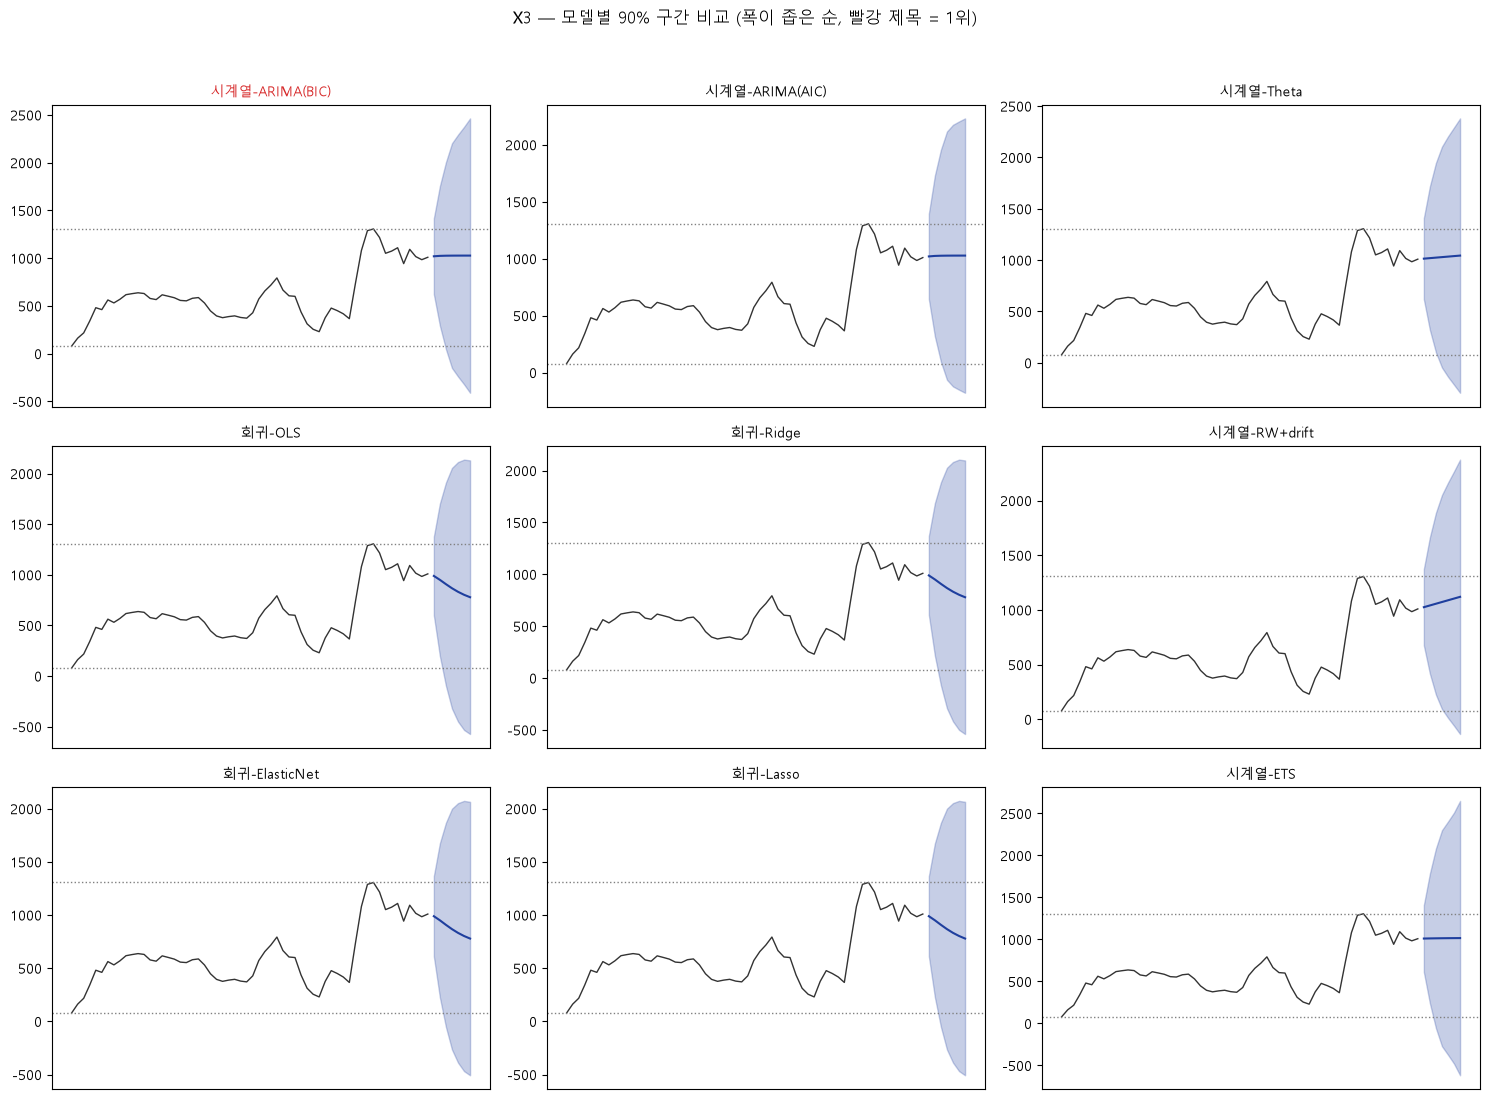

In [7]:
REVERSE_LABELS = {v: k for k, v in FAMILY_LABELS.items()}
FOCUS_VAR = "X3_l1"

def model_band(name, c, safety):
    e = err_df[(err_df["model"] == name) & (err_df["var"] == c)]
    sigma_h = e.groupby("h")["err"].std()
    merged = e.merge(sigma_h.rename("sigma_h"), on="h")
    max_z = merged.groupby("origin").apply(lambda g: (g["err"] / g["sigma_h"]).abs().max())
    k_base = max_z.quantile(0.90)
    return k_base * safety * sigma_h.values

hist = series[FOCUS_VAR]
x_hist, x_fut = range(len(hist)), range(len(hist), len(hist) + H)

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, label in zip(axes.flat, tune_df.index):  # 폭이 좁은 순서(1위부터)로 배치
    name = REVERSE_LABELS[label]
    fc = MODELS[name](hist, H)
    band = model_band(name, FOCUS_VAR, tune_df.loc[label, "safety"])
    ax.plot(x_hist, hist, color="#333", lw=1)
    ax.plot(x_fut, fc, color="#1f3f9e", lw=1.5)
    ax.fill_between(x_fut, fc - band, fc + band, color="#1f3f9e", alpha=0.25)
    ax.axhline(hist.min(), color="gray", ls=":", lw=1)
    ax.axhline(hist.max(), color="gray", ls=":", lw=1)
    ax.set_title(label, fontsize=10, color="#d62728" if label == winner else "black")
    ax.set_xticks([])

fig.suptitle(f"{LABELS[FOCUS_VAR]} — 모델별 90% 구간 비교 (폭이 좁은 순, 빨강 제목 = 1위)", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 부수 검증: 이 순위가 노이즈는 아닌가

3번 노트북과 동일하게, origin을 복원추출(bootstrap)해도 순위가 유지되는지 확인한다.
먼저 기존 방식(safety는 고정하고 origin만 재추출)으로 해본다.


In [8]:
def rel_width_table(name, safety):
    wf = walkforward_coverage_for(name, quantile=0.90, safety=safety)
    wf["rel_width"] = (2 * wf["k"] * wf["sigma_h_mean"]) / wf["var"].map(var_std)
    return wf

optimal_safety = {name: tune_df.loc[FAMILY_LABELS[name], "safety"] for name in MODELS}
per_model = {name: rel_width_table(name, optimal_safety[name]) for name in MODELS}

rng = np.random.default_rng(0)
N_BOOT = 2000
var_origins = {v: sorted(per_model["arima_aic"][per_model["arima_aic"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {name: 0 for name in MODELS}
rank_sum = {name: 0.0 for name in MODELS}
for _ in range(N_BOOT):
    resample_idx = {v: rng.choice(var_origins[v], size=len(var_origins[v]), replace=True) for v in COLS}
    means = {}
    for name in MODELS:
        m = per_model[name]
        vals = []
        for v in COLS:
            sub = m[m["var"] == v].set_index("origin")
            vals.extend(sub.loc[resample_idx[v], "rel_width"].values)
        means[name] = np.mean(vals)
    order = sorted(MODELS, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df_simple = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1),
     "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df_simple)


,1위 비율(%),평균 순위
모델,,
시계열-ARIMA(BIC),100.0,1.00
시계열-ARIMA(AIC),0.0,2.00
시계열-ETS,0.0,8.34
시계열-Theta,0.0,3.01
시계열-RW+drift,0.0,5.74
회귀-OLS,0.0,4.34
회귀-Ridge,0.0,5.42
회귀-Lasso,0.0,8.35
회귀-ElasticNet,0.0,6.80


**해석**: 단순 부트스트랩(safety 고정, origin만 재추출, 2000회)에서는 **ARIMA(BIC)가
전부 1위**(100%)를 차지한다. 그런데 이 방식은 "목표 커버리지에 맞춰 튜닝하는 과정
자체"가 이 데이터에 과적합됐는지는 검증하지 못한다 — safety를 매번 다시 찾도록(중첩)
바꾸면 결과가 달라지는지 아래에서 확인한다.


### 부수 검증 (개선): 중첩+블록 부트스트랩

위 단순 부트스트랩은 "목표 커버리지에 맞춰 튜닝하는 과정 자체"가 이 데이터에
과적합됐는지는 전혀 검증하지 못한다. 이를 보완해 두 가지를 바꾼 부트스트랩을 다시 돈다:

- **중첩(nested)**: 재추출할 때마다 safety를 처음부터 다시 탐색한다(고정하지 않음).
- **블록(block)**: origin을 하나씩이 아니라 4개씩 묶어서 재추출한다 — 확장윈도우 구조상
  인접 origin끼리는 서로 독립이 아니기 때문이다.


In [9]:
def precompute_for_boot(name):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k_base = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            test_max_z = (test_errs / sigma_h).abs().max()
            rows.append({"var": v, "origin": origins[i], "k_base": k_base,
                         "sigma_h_mean": sigma_h.mean(), "test_max_z": test_max_z})
    return pd.DataFrame(rows)

pre_boot = {name: precompute_for_boot(name) for name in MODELS}

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

rng = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
grid = np.arange(1.0, 3.001, 0.02)
var_origin_lists = {v: sorted(pre_boot["arima_aic"][pre_boot["arima_aic"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for _ in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    widths = {}
    for name in MODELS:
        df = pre_boot[name]
        sub = pd.concat(df[df["var"] == v].set_index("origin").loc[resampled[v]] for v in COLS)
        best_width, best_gap = None, np.inf
        for s in grid:
            cov = (sub["test_max_z"] <= sub["k_base"] * s).mean()
            gap = abs(cov - 0.90)
            if gap < best_gap:
                best_gap = gap
                best_width = (2 * sub["k_base"] * s * sub["sigma_h_mean"] / sub["var"].map(var_std)).mean()
        widths[name] = best_width
    order = sorted(MODELS, key=lambda n: widths[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


,1위 비율(%),평균 순위
모델,,
시계열-ARIMA(AIC),66.6,1.53
시계열-ARIMA(BIC),14.8,2.63
회귀-OLS,14.8,3.97
시계열-Theta,2.6,4.10
회귀-Ridge,1.2,5.19
시계열-RW+drift,0.0,6.55
시계열-ETS,0.0,6.21
회귀-Lasso,0.0,7.92
회귀-ElasticNet,0.0,6.90


**해석**: 중첩+블록 부트스트랩(500회)에서는 **ARIMA(AIC)가 1위 비율 66.6%**로
뒤바뀐다 — 단순 부트스트랩에서 100% 1위였던 ARIMA(BIC)는 14.8%로 밀려나고(회귀-OLS와
공동 2위), AIC가 확실한 우세를 보인다. 노트북 3과 정확히 같은 패턴이다 — safety를
고정한 단순 부트스트랩은 과신을 만들어낸다.


### 2-2 최종: 선정 기준을 Winkler(interval) score로 교체

3번 노트북과 동일한 이유로, 90% 튜닝 방식(튜닝 과적합 위험, 불공정 비교)을 **Winkler
score**(90% 단일 수준, α=0.10)로 교체한다 — 프로젝트 목표(90%)는 그대로 유지하면서,
튜닝 없이 커버리지 실패와 구간폭을 하나의 점수로 평가한다.


In [10]:
ALPHA = 0.10  # 90% 단일 수준

def winkler_score(name, alpha):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)  # raw k (safety=1)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            lo, hi = -k * sigma_h, k * sigma_h
            width = hi - lo
            below, above = test_errs < lo, test_errs > hi
            score = width.copy()
            score[below] = width[below] + (2 / alpha) * (lo[below] - test_errs[below])
            score[above] = width[above] + (2 / alpha) * (test_errs[above] - hi[above])
            scores.append(score.mean() / var_std[v])
    return np.mean(scores)

rows = []
for name in MODELS:
    w90 = winkler_score(name, ALPHA)
    rows.append({"모델": FAMILY_LABELS[name], "Winkler@90%": round(w90, 3)})
winkler_combined = pd.DataFrame(rows).set_index("모델").sort_values("Winkler@90%")
display(winkler_combined)

winkler_winner = winkler_combined.index[0]
print(f"Winkler 기준 1위 모델: {winkler_winner}")


,Winkler@90%
모델,
시계열-ARIMA(AIC),5.248
회귀-OLS,5.303
시계열-ARIMA(BIC),5.366
회귀-Ridge,5.516
시계열-Theta,5.907
회귀-ElasticNet,5.933
회귀-Lasso,5.990
시계열-RW+drift,6.129
시계열-ETS,6.150


Winkler 기준 1위 모델: 시계열-ARIMA(AIC)


**해석**: Winkler(90%) 기준으로도 **ARIMA(AIC)가 1위**다(5.248) — ARIMA(BIC)는
5.366으로 3위. 중첩+블록 부트스트랩(위)과 같은 결론이다: **단순 부트스트랩의
"BIC 100%"는 과적합에 의한 착시였고, 제대로 검증하면(중첩+블록이든 Winkler든)
AIC가 낫다.**


**참고**: Winkler는 튜닝(safety 탐색) 과적합 문제는 없앴지만, origin 표본이 변수당
33~37개뿐이라 어떤 지표를 쓰든 순위 자체가 노이즈일 수 있다는 문제는 그대로 남는다.
다만 탐색 단계가 없어 "중첩"할 대상이 없으므로, origin만 블록(4개씩) 재추출하는
block bootstrap(500회)만으로 충분하다.


In [11]:
def precompute_winkler_components(name):
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib_errs = g[g["origin"].isin(origins[:i])]
            sigma_h = calib_errs.groupby("h")["err"].std()
            calib_pivot = calib_errs.pivot(index="origin", columns="h", values="err")
            k = calib_pivot.div(sigma_h, axis=1).abs().max(axis=1).quantile(0.90)
            test_errs = g[g["origin"] == origins[i]].set_index("h")["err"]
            lo, hi = -k * sigma_h, k * sigma_h
            width = hi - lo
            breach = pd.Series(0.0, index=width.index)
            below, above = test_errs < lo, test_errs > hi
            breach[below] = lo[below] - test_errs[below]
            breach[above] = test_errs[above] - hi[above]
            rows.append({"var": v, "origin": origins[i],
                         "width_mean": width.mean() / var_std[v], "breach_mean": breach.mean() / var_std[v]})
    return pd.DataFrame(rows)

pre_wink = {name: precompute_winkler_components(name) for name in MODELS}

def combined_score(df):
    return (df["width_mean"] + (2 / ALPHA) * df["breach_mean"]).mean()

rng = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
var_origin_lists = {v: sorted(pre_wink["arima_aic"][pre_wink["arima_aic"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for _ in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    scores = {}
    for name in MODELS:
        df = pre_wink[name]
        sub = pd.concat(df[df["var"] == v].set_index("origin").loc[resampled[v]] for v in COLS)
        scores[name] = combined_score(sub)
    order = sorted(MODELS, key=lambda n: scores[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

winkler_boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(winkler_boot_df)


,1위 비율(%),평균 순위
모델,,
시계열-ARIMA(AIC),76.6,1.26
회귀-OLS,22.6,1.96
시계열-ARIMA(BIC),0.8,2.80
시계열-Theta,0.0,6.29
시계열-ETS,0.0,8.17
시계열-RW+drift,0.0,8.19
회귀-Ridge,0.0,3.98
회귀-Lasso,0.0,6.84
회귀-ElasticNet,0.0,5.51


**해석**: Winkler 기준 순위도 block bootstrap(500회)에서 **ARIMA(AIC) 1위 비율
76.6%**로 안정적으로 우세하다 — 회귀-OLS가 22.6%로 가끔 앞서고, ARIMA(BIC)는 0.8%까지
떨어진다. 90% 폭 비교(중첩+블록, 66.6%)와 Winkler(76.6%) 두 기준이 이번엔 일관되게
**AIC를 1위**로 지목한다.


## 2-3. 모델 선정

**참고: 90% 튜닝 방식은 왜 버렸나** — 단순 부트스트랩은 ARIMA(BIC) 100%로
보였지만 절차의 과신이었다. 중첩+블록 부트스트랩으로 재검증하면 **ARIMA(AIC)
66.6%로 역전** — 3번 노트북과 같은 패턴. 최종 결정엔 참고용으로만 남긴다.

**최종 기준: Winkler(90%)**

| 검증 | 1위 |
|---|---|
| raw | ARIMA(AIC) — 5.248 |
| block bootstrap | ARIMA(AIC) — 76.6% |

시계열 두 변형이 나머지 7개보다 확실히 우수하고, 재검증된 90% 기준과 Winkler
모두 AIC를 가리켜 서로 다른 방법이 수렴한다.

→ **최종 모델: Auto-ARIMA(AIC)**


## 결론

- 시계열·회귀 두 계열 안에서 9개 모델 비교.
- 단순 부트스트랩은 ARIMA(BIC) 100%로 보였지만 **중첩+블록으로 재검증하니
  AIC가 66.6%로 역전** — 노트북 3과 같은 과신 패턴.
- **최종 기준 Winkler(90%)도 동일하게 AIC 1위**(5.248, bootstrap 76.6%) — 두
  기준 수렴.
- **최종 선정: Auto-ARIMA(AIC)**.
- **한계**: origin 33~37개, 완전 독립적 재검증은 아님.
- **다음 단계**: AIC로 실제 7분기 예측 산출, 이후 ACI로 분기마다 자동 재보정 추가.
